# Frontpage: EDA on Hacker News stories

Run this in Google Colab or Kaggle (fast network). It pulls the cleaned dataset from DagsHub with DVC, then answers the questions that shape the v1 model.

Training data = months with `score_reliable == True` (2024-10 to 2025-11).

In [10]:
!git pull -q
!dvc pull data/hn_stories.parquet.dvc 2>&1 | tail -2

A       data/hn_stories.parquet
1 file fetched and 1 file added


In [11]:
!pip -q install "dvc>=3.50" pandas pyarrow scikit-learn matplotlib
import getpass, os, subprocess
if not os.path.exists("frontpage"):
    subprocess.run(["git", "clone", "-q", "https://github.com/ashfaknawshad/frontpage.git"], check=True)
os.chdir("frontpage")
user = input("DagsHub username: ")
token = getpass.getpass("DagsHub token: ")
subprocess.run(["dvc", "remote", "modify", "origin", "--local", "auth", "basic"], check=True)
subprocess.run(["dvc", "remote", "modify", "origin", "--local", "user", user], check=True)
subprocess.run(["dvc", "remote", "modify", "origin", "--local", "password", token], check=True)
subprocess.run(["dvc", "pull", "data/hn_stories.parquet.dvc"], check=True)

DagsHub username: ashfaknawshad
DagsHub token: ··········


CompletedProcess(args=['dvc', 'pull', 'data/hn_stories.parquet.dvc'], returncode=0)

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "data/hn_stories.parquet"
full = pd.read_parquet(DATA_PATH)
df = full[full["score_reliable"]].copy()
print(f"all rows: {len(full):,}  reliable rows: {len(df):,}  months: {df['month'].nunique()}")
print(f"positive rate (score >= 100): {df['label'].mean():.2%}")
df.head()

all rows: 612,709  reliable rows: 344,072  months: 14
positive rate (score >= 100): 4.68%


,id,title,url,domain,by,kind,posted_at,month,score,descendants,label,score_reliable
0,41703354,Sodium-ion batteries for electric vehicles and...,https://phys.org/news/2024-09-key-problem-sodi...,phys.org,wglb,story,2024-10-01 00:01:09+00:00,2024-10,2,0,False,True
1,41703383,The insatiable hunger of (Open)AI,https://wimvanderbauwhede.codeberg.page/articl...,wimvanderbauwhede.codeberg.page,signa11,story,2024-10-01 00:06:52+00:00,2024-10,13,1,False,True
2,41703395,Creating a Public Counterpoint for AI,https://blog.mozilla.org/en/mozilla/ai/public-...,blog.mozilla.org,donohoe,story,2024-10-01 00:08:41+00:00,2024-10,3,0,False,True
3,41703396,Skiplog: Low-overhead binary-search data struc...,https://old.reddit.com/r/datastructures/commen...,old.reddit.com,gritzko,story,2024-10-01 00:08:51+00:00,2024-10,3,0,False,True
4,41703415,X11 Forwarding and Windows Subsystem for Linux...,https://www.thomasward.com/wsl2-x11/,thomasward.com,smitty1e,story,2024-10-01 00:11:13+00:00,2024-10,4,1,False,True


## 1. Volume and positive rate per month

Is the target stable over time? Does submission volume change (a drift signal for later)?

,stories,positive_rate,reliable
month,,,
2024-10,24463,0.045334,True
2024-11,22247,0.045579,True
2024-12,22564,0.045914,True
2025-01,25086,0.045842,True
2025-02,22445,0.052172,True
2025-03,25331,0.046939,True
2025-04,24427,0.044213,True
2025-05,25279,0.044187,True
2025-06,23844,0.042275,True


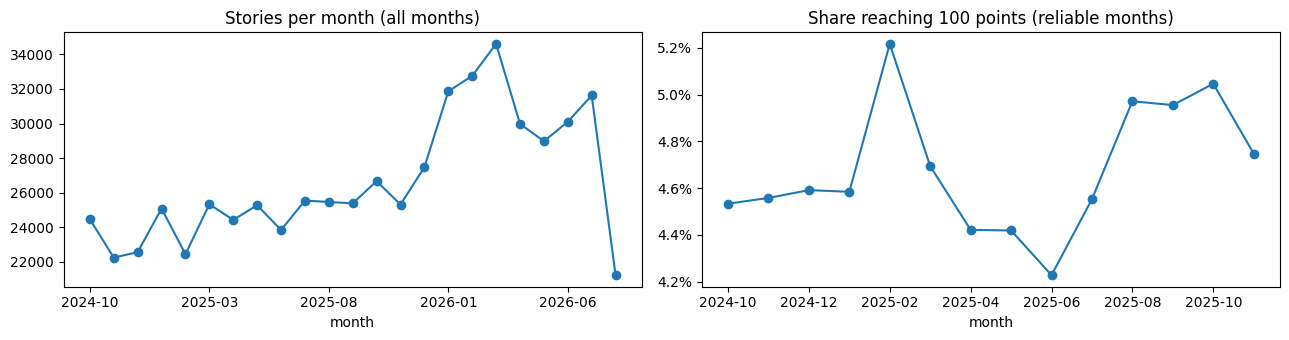

In [13]:
per_month = full.groupby("month").agg(stories=("id", "size"), positive_rate=("label", "mean"), reliable=("score_reliable", "all"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
per_month["stories"].plot(ax=ax[0], marker="o", title="Stories per month (all months)")
per_month.loc[per_month["reliable"], "positive_rate"].plot(ax=ax[1], marker="o", title="Share reaching 100 points (reliable months)")
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
plt.tight_layout(); per_month

## 2. Score distribution

How skewed is it, and how far is 100 from the median?

count    344072.0
mean         19.4
std          77.9
min           1.0
50%           3.0
75%           6.0
90%          28.0
95%          92.0
99%         350.0
max        3406.0
Name: score, dtype: float64


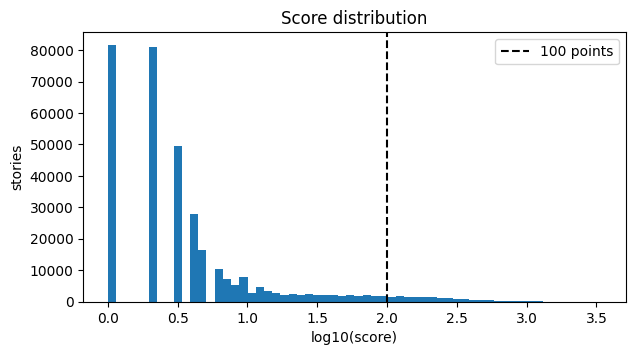

In [14]:
print(df["score"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))
plt.figure(figsize=(7, 3.5))
plt.hist(np.log10(df["score"].clip(lower=1)), bins=60)
plt.axvline(2, color="k", ls="--", label="100 points")
plt.xlabel("log10(score)"); plt.ylabel("stories"); plt.legend(); plt.title("Score distribution");

## 3. Story kind

Show HN / Ask HN / Launch HN vs plain links.

In [15]:
df.groupby("kind").agg(stories=("id", "size"), positive_rate=("label", "mean")).sort_values("positive_rate", ascending=False)

,stories,positive_rate
kind,,
launch,110,0.536364
story,304887,0.049064
show,29548,0.030357
ask,9527,0.020363


## 4. Domains

Which sources reliably get traction? Text posts have no domain.

In [16]:
dom = df.assign(domain=df["domain"].fillna("(text post)")).groupby("domain").agg(stories=("id", "size"), positive_rate=("label", "mean"))
print(f"distinct domains: {len(dom):,}; domains with >= 200 stories: {(dom['stories'] >= 200).sum()}")
dom[dom["stories"] >= 200].sort_values("positive_rate", ascending=False).head(25)

distinct domains: 73,527; domains with >= 200 stories: 127


,stories,positive_rate
domain,,
anthropic.com,240,0.208333
lwn.net,407,0.176904
eff.org,222,0.171171
openai.com,316,0.170886
simonwillison.net,346,0.150289
seangoedecke.com,206,0.140777
quantamagazine.org,509,0.133595
blog.google,343,0.131195
smithsonianmag.com,304,0.128289


In [17]:
dom[dom["stories"] >= 200].sort_values("positive_rate").head(15)

,stories,positive_rate
domain,,
scworld.com,223,0.000000
mdpi.com,486,0.002058
securityweek.com,361,0.002770
web.archive.org,320,0.003125
socket.dev,229,0.004367
chromewebstore.google.com,672,0.007440
marginalrevolution.com,259,0.007722
coindesk.com,259,0.007722
scmp.com,252,0.007937


## 5. When it was posted (UTC)

Hour of week matters if the audience is time-zone shaped.

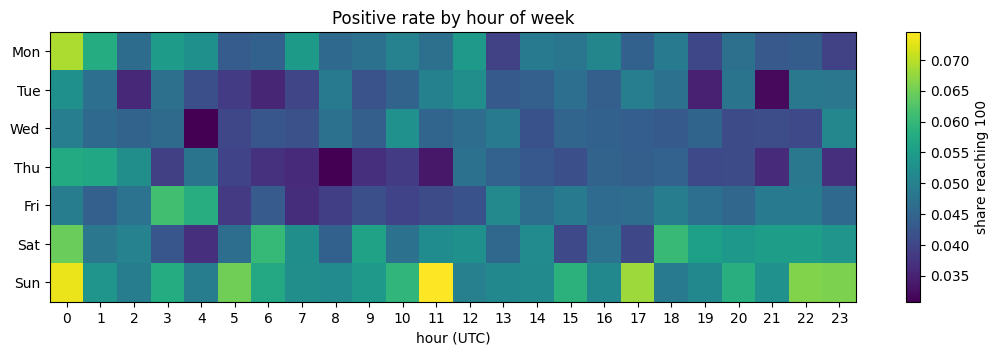

In [18]:
t = df["posted_at"].dt.tz_convert("UTC")
grid = df.assign(dow=t.dt.dayofweek, hour=t.dt.hour).pivot_table(index="dow", columns="hour", values="label", aggfunc="mean")
plt.figure(figsize=(13, 3.5))
plt.imshow(grid, aspect="auto", cmap="viridis")
plt.colorbar(label="share reaching 100")
plt.yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); plt.xticks(range(24)); plt.xlabel("hour (UTC)")
plt.title("Positive rate by hour of week");

## 6. Title shape

In [19]:
shape = df.assign(
    title_len=df["title"].str.len(),
    has_number=df["title"].str.contains(r"\d"),
    has_question=df["title"].str.contains(r"\?"),
    has_year_tag=df["title"].str.contains(r"\(\d{4}\)"),
)
print(shape.groupby(pd.cut(shape["title_len"], [0, 20, 40, 60, 80, 200]), observed=True)["label"].agg(["size", "mean"]))
for col in ["has_number", "has_question", "has_year_tag"]:
    print(shape.groupby(col)["label"].agg(["size", "mean"]).rename_axis(col), "\n")

             size      mean
title_len                  
(0, 20]     22157  0.058943
(20, 40]    79756  0.055294
(40, 60]   114053  0.047495
(60, 80]   127083  0.038927
(80, 200]    1023  0.028348
              size      mean
has_number                  
False       273366  0.044102
True         70706  0.057322 

                size      mean
has_question                  
False         317822  0.048134
True           26250  0.030895 

                size      mean
has_year_tag                  
False         331683  0.045408
True           12389  0.084591 



## 7. Words that separate hits from misses

Smoothed log-odds of each word appearing in a hit vs a miss title. This is what the TF-IDF model will pick up.

In [20]:
from sklearn.feature_extraction.text import CountVectorizer
vec = CountVectorizer(min_df=50, stop_words="english", binary=True)
X = vec.fit_transform(df["title"])
y = df["label"].to_numpy()
hits = np.asarray(X[y].sum(axis=0)).ravel() + 1
misses = np.asarray(X[~y].sum(axis=0)).ravel() + 1
log_odds = np.log(hits / y.sum()) - np.log(misses / (~y).sum())
terms = pd.Series(log_odds, index=vec.get_feature_names_out())
pd.DataFrame({"most hit-like": terms.nlargest(20).index, "most miss-like": terms.nsmallest(20).index})

,most hit-like,most miss-like
0,ublock,warns
1,died,seo
2,illustrated,taiwan
3,kagi,newsletter
4,grapheneos,billionaire
5,forth,misinformation
6,ffmpeg,podcasts
7,lisp,survey
8,drm,cms
9,rot,chinese


## 8. What I learned (fill in)

- Positive rate: …
- Strongest signals: …
- Weak or surprising: …
- Decisions for v1 features: …
- Drift to watch in the live stream: …

Paste these into the README; reviewers read this section.